# 热力图

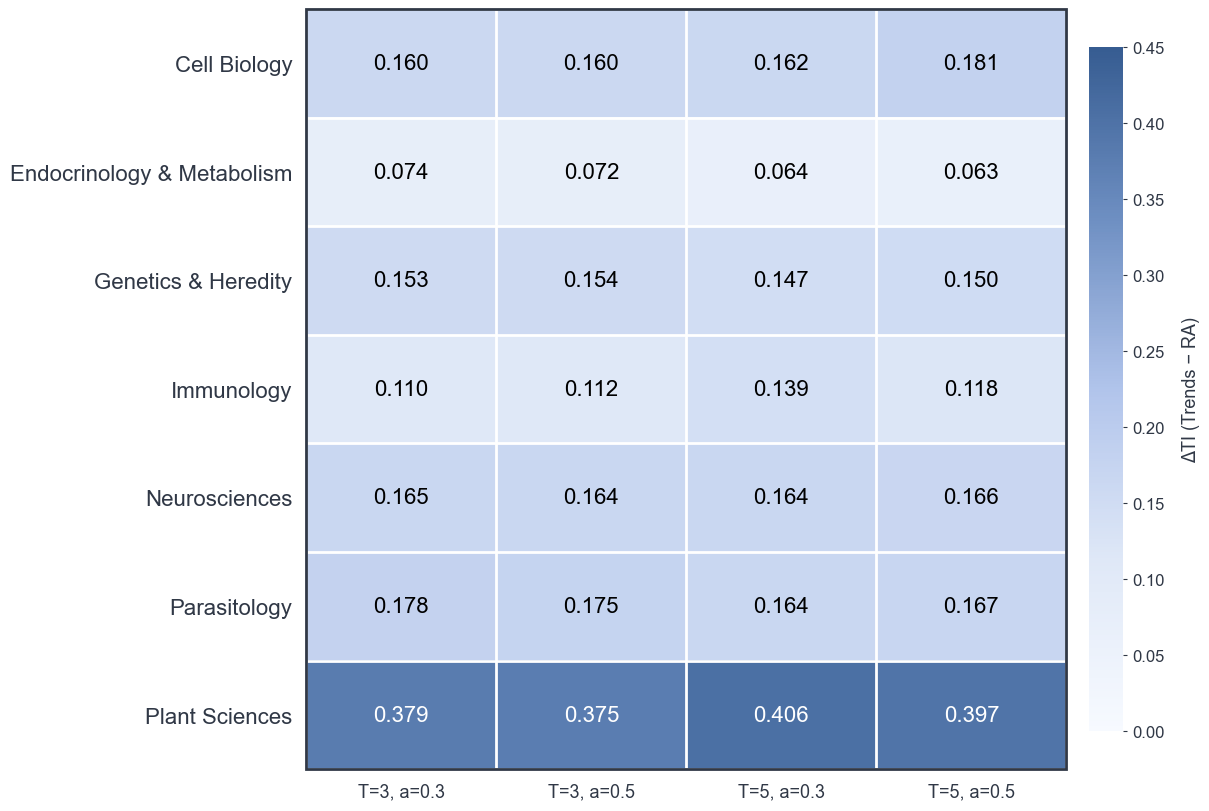

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import FormatStrFormatter
from matplotlib.patches import Rectangle

# ==================== 数据 ====================
categories = [
    "Cell Biology",
    "Endocrinology & Metabolism",
    "Genetics & Heredity",
    "Immunology",
    "Neurosciences",
    "Parasitology",
    "Plant Sciences",
]

# 列顺序与最新表格一致
parameter_labels = [
    "T=3, a=0.3",
    "T=3, a=0.5",
    "T=5, a=0.3",
    "T=5, a=0.5",
]

# 每行对应一个学科，每列对应一种参数组合
ra = np.array([
    [-0.296, -0.295, -0.305, -0.321],  # Cell Biology
    [-0.258, -0.254, -0.268, -0.261],  # Endocrinology & Metabolism
    [-0.232, -0.233, -0.231, -0.232],  # Genetics & Heredity
    [-0.272, -0.270, -0.301, -0.276],  # Immunology
    [-0.213, -0.212, -0.215, -0.214],  # Neurosciences
    [-0.459, -0.454, -0.455, -0.462],  # Parasitology
    [-0.391, -0.389, -0.414, -0.409],  # Plant Sciences
])

trends = np.array([
    [-0.136, -0.135, -0.143, -0.140],
    [-0.184, -0.182, -0.204, -0.198],
    [-0.079, -0.079, -0.084, -0.082],
    [-0.162, -0.158, -0.162, -0.158],
    [-0.048, -0.048, -0.051, -0.048],
    [-0.281, -0.279, -0.291, -0.295],
    [-0.012, -0.014, -0.008, -0.012],
])

# 计算差值；单位为 TI，不是百分比
delta = trends - ra

# ==================== 可调整参数 ====================
FIGSIZE = (12, 8)
FONT_SIZE = 16
ANNOTATION_SIZE = 16
SAVE_FIGURE = False

# ==================== 字体与导出设置 ====================
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "DejaVu Sans"],
    "font.size": FONT_SIZE,
    "text.color": "#303846",
    "axes.labelcolor": "#303846",
    "xtick.color": "#303846",
    "ytick.color": "#303846",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.grid": False,
    "pdf.fonttype": 42,
    "svg.fonttype": "none",
})

# 延续前面的蓝色配色，由浅到深表示差值增大
cmap = LinearSegmentedColormap.from_list(
    "ti_difference_blue",
    [
        "#F7FAFF",
        "#DFE8F7",
        "#B1C4EB",
        "#6E8FC2",
        "#365C91",
    ]
)

# ==================== 绘制热力图 ====================
fig, ax = plt.subplots(
    figsize=FIGSIZE,
    layout="constrained"
)

# 本组差值全部为正，色条从 0 开始
# 上限向上取整至 0.05 的倍数，本组数据得到 0.45
vmax = np.ceil(delta.max() / 0.05) * 0.05

heatmap = ax.imshow(
    delta,
    cmap=cmap,
    vmin=0,
    vmax=vmax,
    aspect="auto",
    interpolation="nearest"
)

# ==================== 坐标轴 ====================
ax.set_xticks(np.arange(len(parameter_labels)))
ax.set_xticklabels(parameter_labels, fontsize=13)

ax.set_yticks(np.arange(len(categories)))
ax.set_yticklabels(categories, fontsize=FONT_SIZE)

# ax.set_xlabel("Parameter setting", labelpad=12)
# ax.set_ylabel("WOS category", labelpad=14)

# ax.set_title(
#     "Mean TI difference across parameter settings",
#     fontsize=16,
#     pad=16
# )

ax.tick_params(axis="both", which="major", length=0, pad=10)

# 白色单元格分隔线
ax.set_xticks(
    np.arange(-0.5, len(parameter_labels), 1),
    minor=True
)
ax.set_yticks(
    np.arange(-0.5, len(categories), 1),
    minor=True
)
ax.grid(
    which="minor",
    color="white",
    linestyle="-",
    linewidth=2
)
ax.tick_params(which="minor", bottom=False, left=False)

for spine in ax.spines.values():
    spine.set_visible(False)

# ==================== 单元格数值 ====================
for i in range(delta.shape[0]):
    for j in range(delta.shape[1]):
        value = delta[i, j]

        # 根据背景颜色选择对比度更高的黑色或白色文字
        rgb = np.array(cmap(heatmap.norm(value))[:3])
        # linear_rgb = np.where(
        #     rgb <= 0.04045,
        #     rgb / 12.92,
        #     ((rgb + 0.055) / 1.055) ** 2.4
        # )
        linear_rgb = np.where(
            rgb <= 0.04045,
            rgb / 12.92,
            ((rgb + 0.055) / 1.055) ** 2.4
        )
        luminance = np.dot(
            linear_rgb,
            [0.2126, 0.7152, 0.0722]
        )
        text_color = "black" if luminance > 0.25 else "white"

        ax.text(
            j, i,
            f"{value:.3f}",
            ha="center",
            va="center",
            fontsize=ANNOTATION_SIZE,
            color=text_color
        )

# ==================== 最外层边框 ====================
ax.add_patch(
    Rectangle(
        (-0.5, -0.5),
        len(parameter_labels),
        len(categories),
        fill=False,
        edgecolor="#303846",
        linewidth=2,
        zorder=10,
        clip_on=False,
    )
)

# ==================== 色条 ====================
cbar = fig.colorbar(
    heatmap,
    ax=ax,
    fraction=0.045,
    pad=0.03
)

cbar.set_label(
    "ΔTI (Trends − RA)",
    fontsize=13,
    labelpad=12
)
cbar.ax.yaxis.set_major_formatter(FormatStrFormatter("%.2f"))
cbar.ax.tick_params(labelsize=12, length=3)
cbar.outline.set_visible(False)

# # ==================== 可选保存 ====================
# if SAVE_FIGURE:
#     output_dir = (
#         Path(__file__).resolve().parent
#         if "__file__" in globals()
#         else Path.cwd()
#     )

#     fig.savefig(output_dir / "ti_parameter_heatmap.png", dpi=600)
#     fig.savefig(output_dir / "ti_parameter_heatmap.pdf")
#     fig.savefig(output_dir / "ti_parameter_heatmap.svg")

plt.show()

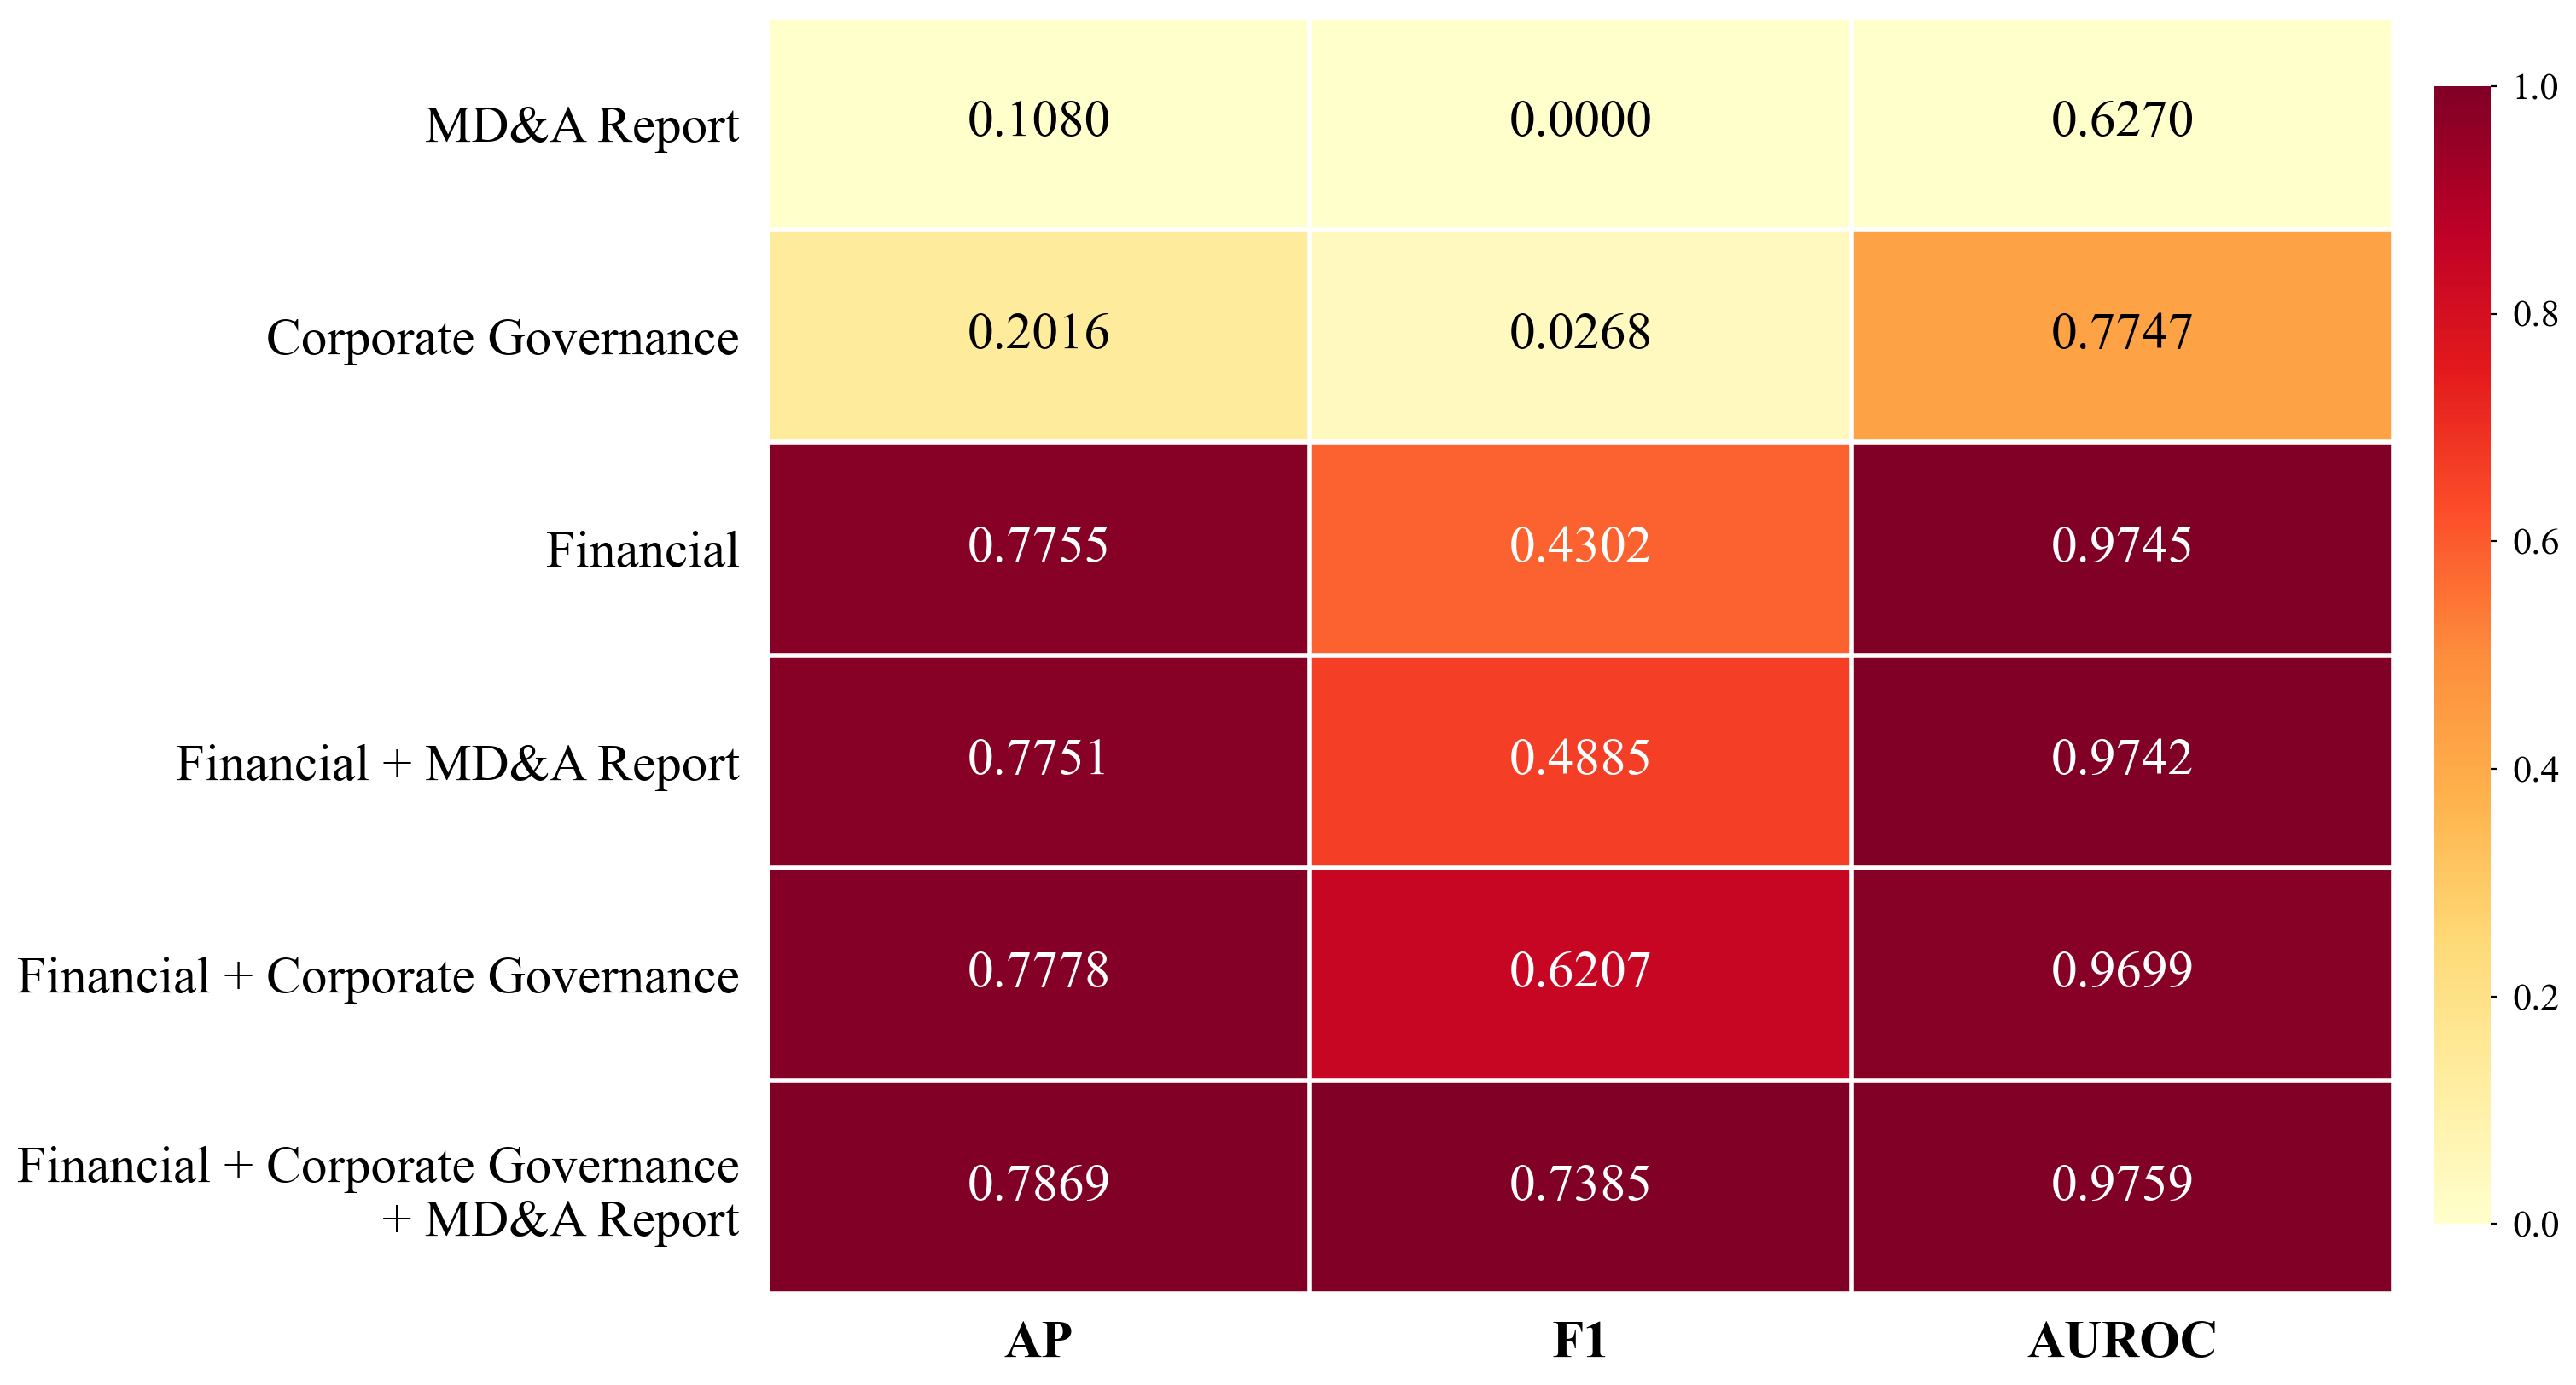

In [16]:
import numpy as np
import matplotlib.pyplot as plt

# 统一字体
plt.rcParams.update({
    "font.family": "Times New Roman",
    "font.size": 18,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

# 字号集中设置
COL_SIZE = 22       # 列指标名称
ROW_SIZE = 22       # 行模态名称
VALUE_SIZE = 22     # 格子内数值
CBAR_SIZE = 18      # 色条标题
CBAR_TICK_SIZE = 16 # 色条刻度

# 原始数据
rows_all = [
    "Financial + Corporate Governance + MD&A Report",
    "Financial + Corporate Governance",
    "Financial + MD&A Report",
    "Financial",
    "Corporate Governance",
    "MD&A Report",
]

mean_all = np.array([
    [0.7869, 0.7385, 0.9759],
    [0.7778, 0.6207, 0.9699],
    [0.7751, 0.4885, 0.9742],
    [0.7755, 0.4302, 0.9745],
    [0.2016, 0.0268, 0.7747],
    [0.1080, 0.0000, 0.6270],
])

# 单模态 → 双模态 → 全模态
order = [5, 4, 3, 2, 1, 0]
rows = [rows_all[i] for i in order]
mean = mean_all[order]

# 最长的标签分成两行
row_labels = rows.copy()
row_labels[-1] = "Financial + Corporate Governance\n+ MD&A Report"

cols = ["AP", "F1", "AUROC"]

# 每个指标分别归一化，仅用于颜色映射
norm = np.zeros_like(mean)
for j in range(mean.shape[1]):
    cmin = mean[:, j].min()
    cmax = mean[:, j].max()
    norm[:, j] = (
        (mean[:, j] - cmin) / (cmax - cmin)
        if cmax > cmin else 0.5
    )

# 创建画布
fig, ax = plt.subplots(
    figsize=(15, 8),
    dpi=200,
    layout="constrained",
)

im = ax.imshow(
    norm,
    cmap="YlOrRd",
    aspect="auto",
    vmin=0,
    vmax=1,
)

# 坐标轴标签
ax.set_xticks(np.arange(len(cols)))
ax.set_yticks(np.arange(len(rows)))

ax.set_xticklabels(
    cols,
    fontsize=COL_SIZE,
    fontweight="bold",
)

ax.set_yticklabels(
    row_labels,
    fontsize=ROW_SIZE,
    linespacing=1.2,
)

ax.tick_params(axis="x", which="major", length=0, pad=12)
ax.tick_params(axis="y", which="major", length=0, pad=12)

# 单元格之间的白色分隔线
ax.set_xticks(np.arange(-0.5, len(cols), 1), minor=True)
ax.set_yticks(np.arange(-0.5, len(rows), 1), minor=True)
ax.grid(
    which="minor",
    color="white",
    linestyle="-",
    linewidth=2,
)
ax.tick_params(
    which="minor",
    bottom=False,
    top=False,
    left=False,
    right=False,
)

for spine in ax.spines.values():
    spine.set_visible(False)

# 格子内数值：Times New Roman 常规体
for i in range(len(rows)):
    for j in range(len(cols)):
        text_color = "white" if norm[i, j] > 0.55 else "black"

        ax.text(
            j, i,
            f"{mean[i, j]:.4f}",
            ha="center",
            va="center",
            fontfamily="Times New Roman",
            fontstyle="normal",
            fontweight="normal",   # 取消数字加粗
            fontsize=22,
            color=text_color,
        )

# 色条
cbar = fig.colorbar(
    im,
    ax=ax,
    fraction=0.035,
    pad=0.025,
)

# cbar.set_label(
#     "Normalized score (per metric)",
#     fontsize=CBAR_SIZE,
#     labelpad=14,
# )
cbar.set_ticks(np.linspace(0, 1, 6))
cbar.ax.tick_params(
    labelsize=CBAR_TICK_SIZE,
    length=3,
    pad=6,
)
cbar.outline.set_visible(False)

# 保存时取消注释
# fig.savefig("modality_heatmap.pdf", bbox_inches="tight")
# fig.savefig("modality_heatmap.png", dpi=300, bbox_inches="tight")

plt.show()